# Анализ цен на квартиры в Москве

**Вопрос:** какие характеристики квартиры связаны с ценой и можно ли предсказать цену по её параметрам?

**Данные:** [Prices of Moscow apartments — Kaggle](https://www.kaggle.com/datasets/ivan314sh/prices-of-moscow-apartments)


In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
FIGURES_DIR = "../figures"
os.makedirs(FIGURES_DIR, exist_ok=True)
DATA_PATH = "../data/moscow_flats_dataset_eng.csv"
df = pd.read_csv(DATA_PATH)
df.head()

,price,min_to_metro,region_of_moscow,total_area,living_area,floor,number_of_floors,construction_year,is_new,is_apartments,ceiling_height,number_of_rooms,link
0,31633073.0,24.0,SAR,64.2,32.4,11.0,16.0,2023.0,1.0,0.0,3.15,2.0,https://www.cian.ru/sale/flat/293204033/
1,29293000.0,9.0,NEAR,78.1,NaN,9.0,27.0,2022.0,1.0,0.0,NaN,2.0,https://www.cian.ru/sale/flat/294033524/
2,30349669.0,5.0,SAR,72.4,33.6,3.0,24.0,2023.0,1.0,0.0,3.15,2.0,https://www.cian.ru/sale/flat/300712697/
3,31845511.0,19.0,SAR,69.2,NaN,2.0,12.0,2024.0,1.0,0.0,2.97,2.0,https://www.cian.ru/sale/flat/300228448/
4,38810000.0,27.0,WAR,66.9,24.8,9.0,14.0,2023.0,1.0,0.0,3.00,2.0,https://www.cian.ru/sale/flat/299262105/


In [18]:
print("Размер данных:", df.shape)
df.info()
display(df.isna().sum().sort_values(ascending=False))
print("Дубликаты:", df.duplicated().sum())

Размер данных: (6983, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6983 entries, 0 to 6982
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   price              6961 non-null   float64
 1   min_to_metro       6846 non-null   float64
 2   region_of_moscow   6892 non-null   object 
 3   total_area         6960 non-null   float64
 4   living_area        4514 non-null   float64
 5   floor              6960 non-null   float64
 6   number_of_floors   6960 non-null   float64
 7   construction_year  5761 non-null   float64
 8   is_new             6949 non-null   float64
 9   is_apartments      6949 non-null   float64
 10  ceiling_height     5053 non-null   float64
 11  number_of_rooms    6983 non-null   float64
 12  link               6983 non-null   object 
dtypes: float64(11), object(2)
memory usage: 709.3+ KB


living_area          2469
ceiling_height       1930
construction_year    1222
min_to_metro          137
region_of_moscow       91
is_new                 34
is_apartments          34
total_area             23
floor                  23
number_of_floors       23
price                  22
number_of_rooms         0
link                    0
dtype: int64

Дубликаты: 3


In [19]:
def find_column(columns, variants):
    columns_lower = {c.lower().strip(): c for c in columns}
    for variant in variants:
        for col_lower, original in columns_lower.items():
            if variant in col_lower:
                return original
    return None

price_col = find_column(df.columns, ["price", "цена"])
area_col = find_column(df.columns, ["area", "total_area", "square", "площад"])
rooms_col = find_column(df.columns, ["room", "комн"])

print("Цена:", price_col)
print("Площадь:", area_col)
print("Комнаты:", rooms_col)

if price_col is None or area_col is None:
    raise ValueError("Не найдены колонки цены или площади. Посмотри df.columns и поправь названия вручную.")

Цена: price
Площадь: total_area
Комнаты: number_of_rooms


In [20]:
df = df.dropna(subset=[price_col, area_col]).copy()
df = df.drop_duplicates()

df[price_col] = pd.to_numeric(df[price_col], errors="coerce")
df[area_col] = pd.to_numeric(df[area_col], errors="coerce")
df = df.dropna(subset=[price_col, area_col])
df = df[(df[price_col] > 0) & (df[area_col] > 0)]
df = df[(df[area_col] >= 10) & (df[area_col] <= 300)]
df = df[(df[price_col] >= 1_000_000) & (df[price_col] <= 500_000_000)]

df["price_per_sqm"] = df[price_col] / df[area_col]
print("После очистки:", df.shape)
df[[price_col, area_col, "price_per_sqm"]].describe()

После очистки: (6904, 14)


,price,total_area,price_per_sqm
count,6.904000e+03,6904.000000,6.904000e+03
mean,5.587163e+07,82.491806,5.616259e+05
std,6.962762e+07,47.772718,3.709330e+05
min,1.000000e+06,10.100000,1.890359e+04
25%,1.649975e+07,45.000000,3.212697e+05
50%,3.014770e+07,70.300000,4.496400e+05
75%,6.012500e+07,105.000000,6.400291e+05
max,5.000000e+08,300.000000,3.716553e+06


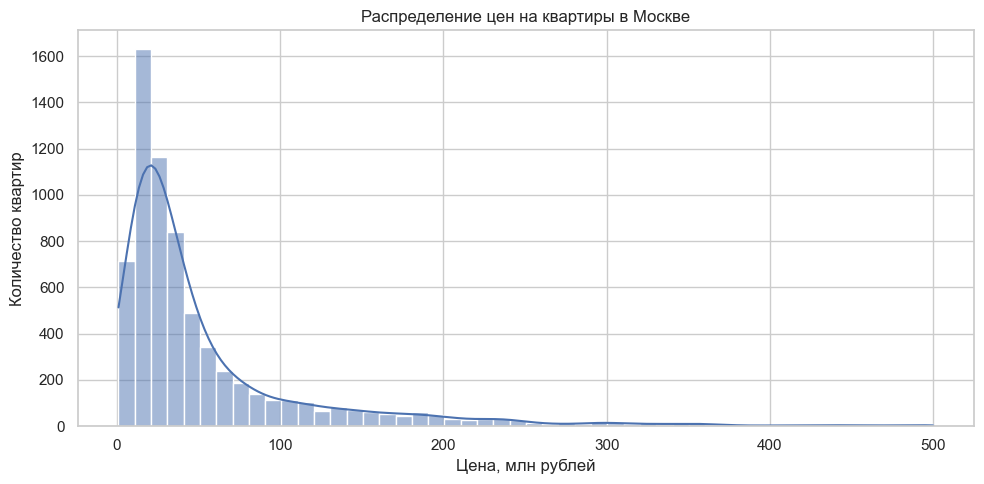

In [21]:
plt.figure(figsize=(10, 5))
sns.histplot(df[price_col] / 1_000_000, bins=50, kde=True)
plt.xlabel("Цена, млн рублей")
plt.ylabel("Количество квартир")
plt.title("Распределение цен на квартиры в Москве")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/price_distribution.png", dpi=150)
plt.show()

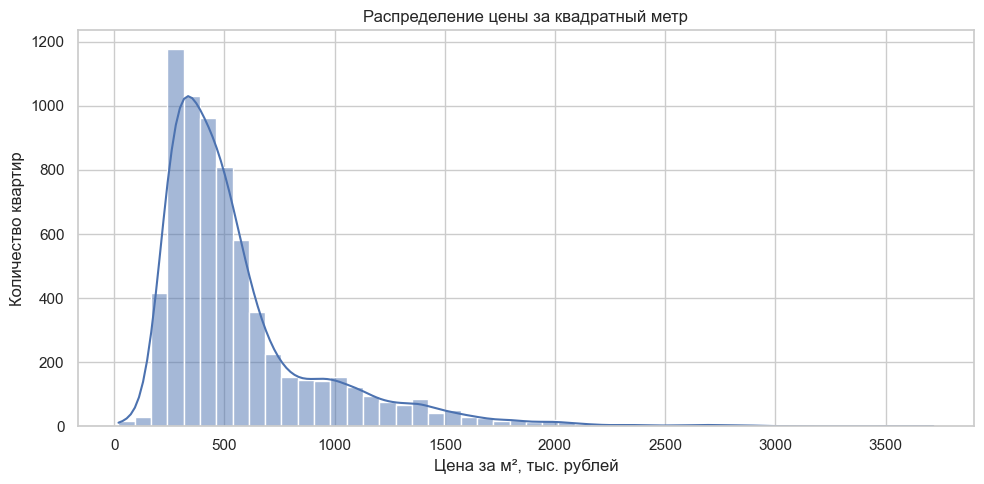

In [22]:
plt.figure(figsize=(10, 5))
sns.histplot(df["price_per_sqm"] / 1000, bins=50, kde=True)
plt.xlabel("Цена за м², тыс. рублей")
plt.ylabel("Количество квартир")
plt.title("Распределение цены за квадратный метр")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/price_per_sqm_distribution.png", dpi=150)
plt.show()

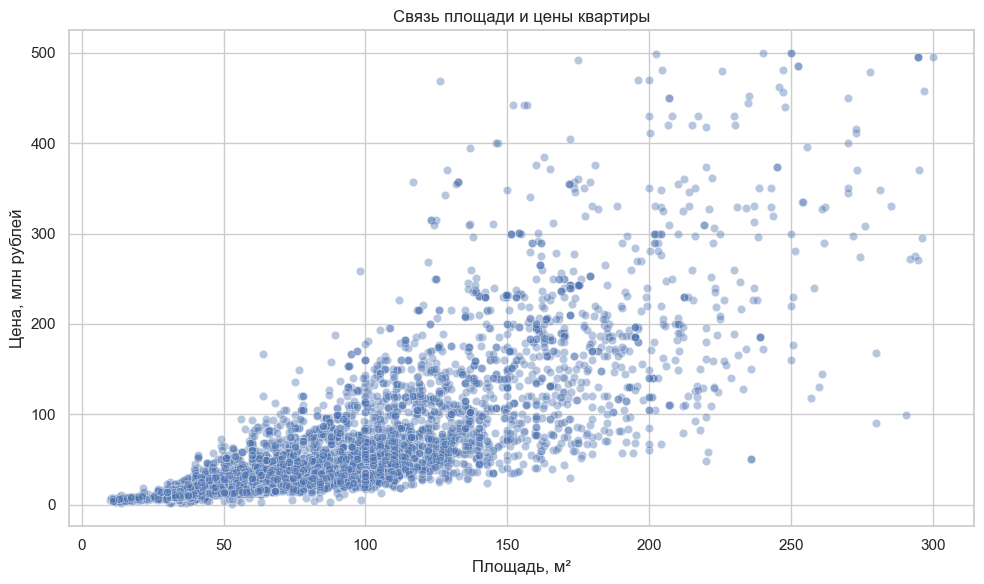

Корреляция площади и цены: 0.80


In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x=area_col,
    y=df[price_col] / 1_000_000,
    alpha=0.4
)

plt.xlabel("Площадь, м²")
plt.ylabel("Цена, млн рублей")
plt.title("Связь площади и цены квартиры")

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/area_vs_price.png", dpi=150)
plt.show()

correlation = df[[area_col, price_col]].corr().iloc[0, 1]
print(f"Корреляция площади и цены: {correlation:.2f}")

,count,median,mean
number_of_rooms,,,
1.0,1597,12500000.0,1.512925e+07
2.0,2031,26760111.0,3.541715e+07
3.0,1698,50509247.5,8.200893e+07
4.0,1578,57390000.0,9.530602e+07


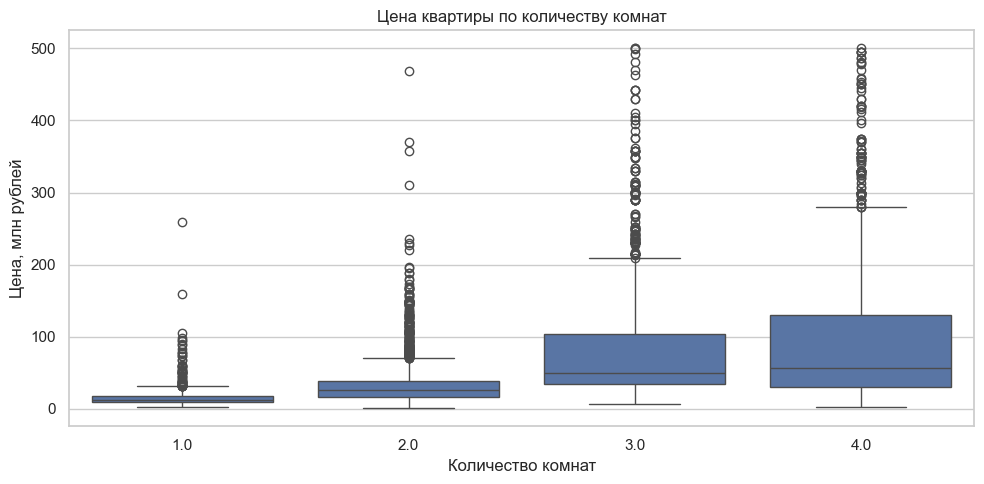

In [24]:
if rooms_col:
    rooms_stats = (
        df.groupby(rooms_col)[price_col]
        .agg(["count", "median", "mean"])
        .sort_index()
    )
    display(rooms_stats)

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=df,
        x=rooms_col,
        y=df[price_col] / 1_000_000
    )

    plt.xlabel("Количество комнат")
    plt.ylabel("Цена, млн рублей")
    plt.title("Цена квартиры по количеству комнат")

    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/rooms_vs_price.png", dpi=150)
    plt.show()

else:
    print("Колонка с числом комнат не найдена.")

In [25]:
feature_columns = [area_col]
if rooms_col:
    df[rooms_col] = pd.to_numeric(df[rooms_col], errors="coerce")
    df = df.dropna(subset=[rooms_col])
    feature_columns.append(rooms_col)

X = df[feature_columns]
y = df[price_col]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (5523, 2)
Тестовая выборка: (1381, 2)


In [26]:
median_price = y_train.median()
baseline_predictions = np.full(len(y_test), median_price)

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print(f"Baseline MAE: {baseline_mae:,.0f} рублей")
print(f"Baseline RMSE: {baseline_rmse:,.0f} рублей")
print(f"Baseline R²: {baseline_r2:.3f}")

Baseline MAE: 37,558,555 рублей
Baseline RMSE: 72,401,752 рублей
Baseline R²: -0.136


In [27]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print(f"Linear Regression MAE: {linear_mae:,.0f} рублей")
print(f"Linear Regression RMSE: {linear_rmse:,.0f} рублей")
print(f"Linear Regression R²: {linear_r2:.3f}")

Linear Regression MAE: 22,734,531 рублей
Linear Regression RMSE: 38,201,562 рублей
Linear Regression R²: 0.684


In [28]:
rf_model = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print(f"Random Forest MAE: {rf_mae:,.0f} рублей")
print(f"Random Forest RMSE: {rf_rmse:,.0f} рублей")
print(f"Random Forest R²: {rf_r2:.3f}")

Random Forest MAE: 22,207,836 рублей
Random Forest RMSE: 42,517,909 рублей
Random Forest R²: 0.608


In [29]:
results = pd.DataFrame({
    "Модель": ["Baseline: медиана", "Linear Regression", "Random Forest"],
    "MAE, руб.": [baseline_mae, linear_mae, rf_mae],
    "RMSE, руб.": [baseline_rmse, linear_rmse, rf_rmse],
    "R²": [baseline_r2, linear_r2, rf_r2]
})
results

,Модель,"MAE, руб.","RMSE, руб.",R²
0,Baseline: медиана,3.755856e+07,7.240175e+07,-0.136327
1,Linear Regression,2.273453e+07,3.820156e+07,0.683650
2,Random Forest,2.220784e+07,4.251791e+07,0.608124


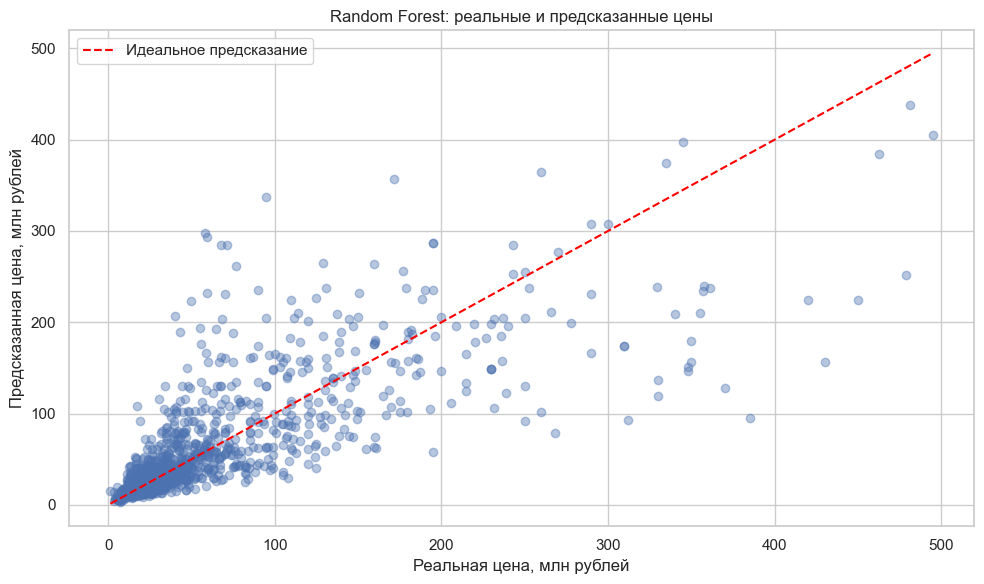

In [30]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test / 1_000_000, rf_predictions / 1_000_000, alpha=0.4)
plt.plot([y_test.min() / 1_000_000, y_test.max() / 1_000_000],
         [y_test.min() / 1_000_000, y_test.max() / 1_000_000],
         color="red", linestyle="--", label="Идеальное предсказание")
plt.xlabel("Реальная цена, млн рублей")
plt.ylabel("Предсказанная цена, млн рублей")
plt.title("Random Forest: реальные и предсказанные цены")
plt.legend()
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/random_forest_predictions.png", dpi=150)
plt.show()

## Выводы

- Площадь квартиры связана с ценой: корреляция равна 0.80. Это означает, что площадь является важным фактором при объяснении различий в цене квартир.
- Baseline-модель, которая всегда предсказывает медианную цену, показала MAE 37.56 млн рублей и R² -0.14. Это подтверждает, что предсказание одной средней ценой не объясняет различия между квартирами.
- Linear Regression показала MAE 22.73 млн рублей, RMSE 38.20 млн рублей и R² 0.684.
- Random Forest показал MAE 22.21 млн рублей, RMSE 42.52 млн рублей и R² 0.608.
- Лучшая модель по MAE — Random Forest. Однако Linear Regression имеет более высокий R² и более низкий RMSE, поэтому её результаты также сильные и её проще интерпретировать.
- Модель можно улучшить, добавив район, расстояние до метро, этаж, год постройки, тип дома и другие характеристики квартиры.